# Real Sundarbans network vs. random trees (18 Jan 2016)

**Question:** in what ways, and by how much, does the real channel network differ from a tree?

One hand-built tree is a single example and can't tell us what is *typical* of trees. So we generate **1,000 random trees** of each of two kinds on the **same nodes** as the real network.
That gives the spread of each parameter among trees, and we can say whether the real value is unusual (percentile, z-score).

| | Random **channel** tree (null 1) | Random **parent** tree (null 2) |
|---|---|---|
| construction | cut the real network's loops at random: a uniform random spanning forest rooted at the outlets (Wilson's algorithm) | every junction and inlet picks a **random parent** among nodes already placed, anywhere on the map. Outlets are roots, inlets are leaves, junctions take ≤ 2 children (degree ≤ 3, like real junctions) |
| keeps | nodes, roles, **only real channels**, geography | nodes, roles, max degree |
| ignores | which channels form loops | geography: links can join any two nodes |
| real vs this null shows | **what the loops add** | **what loops + geography add** |

Both nulls have 104 nodes and 95 links (a forest with one tree per outlet). The real network has 121 links, i.e. 26 more.

Kernel: *Python (rivgraph)*. The null models and metrics are in `tree_nulls.py`, and the image → graph pipeline is in `sundarbans_rg.py`.

In [1]:
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt, warnings
from matplotlib.lines import Line2D
from sundarbans_rg import extract_network
import tree_nulls as tn
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

net = extract_network('18th Jan 2016.tiff', 'example_2016')
rn, G, D = net['rn'], net['G'], net['D']
inlets, outlets = list(rn.nodes['inlets']), list(rn.nodes['outlets'])
print(f'real network: {G.number_of_nodes()} nodes, {G.number_of_edges()} links, {len(inlets)} inlets, {len(outlets)} outlets')

T = net['transform']; H, W = rn.imshape
POS = {n: ((d['pos'][0] - T.c) / 1e3, (d['pos'][1] - (T.f + H * T.e)) / 1e3) for n, d in G.nodes(data=True)}
KIND_COL = {'inlet': '#2ca02c', 'outlet': '#ff7f0e', 'junction': '#444444'}
COL = {'real': 'black', 'channel tree': '#2b8cbe', 'parent tree': '#e6550d'}
EXT = [0, W * T.a / 1e3, 0, H * (-T.e) / 1e3]; EXT_TOP = EXT[3]

Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.


real network: 104 nodes, 121 links, 26 inlets, 9 outlets


## 0. The cleaned RivGraph network, with node labels

Labels for cross-checking between figures:
* **I1…I26:** inlets, numbered west → east along the top edge, then down the sides.
* **O1…O9:** outlets, numbered west → east.
* **J1…J69:** junctions, numbered north → south in 5-km bands, west → east within a band.

Only inlets, outlets and the 15 junctions with the highest betweenness are labelled on the maps. Every label is listed in `example_2016/node_labels.csv`, with its RivGraph node id, degree and coordinates.

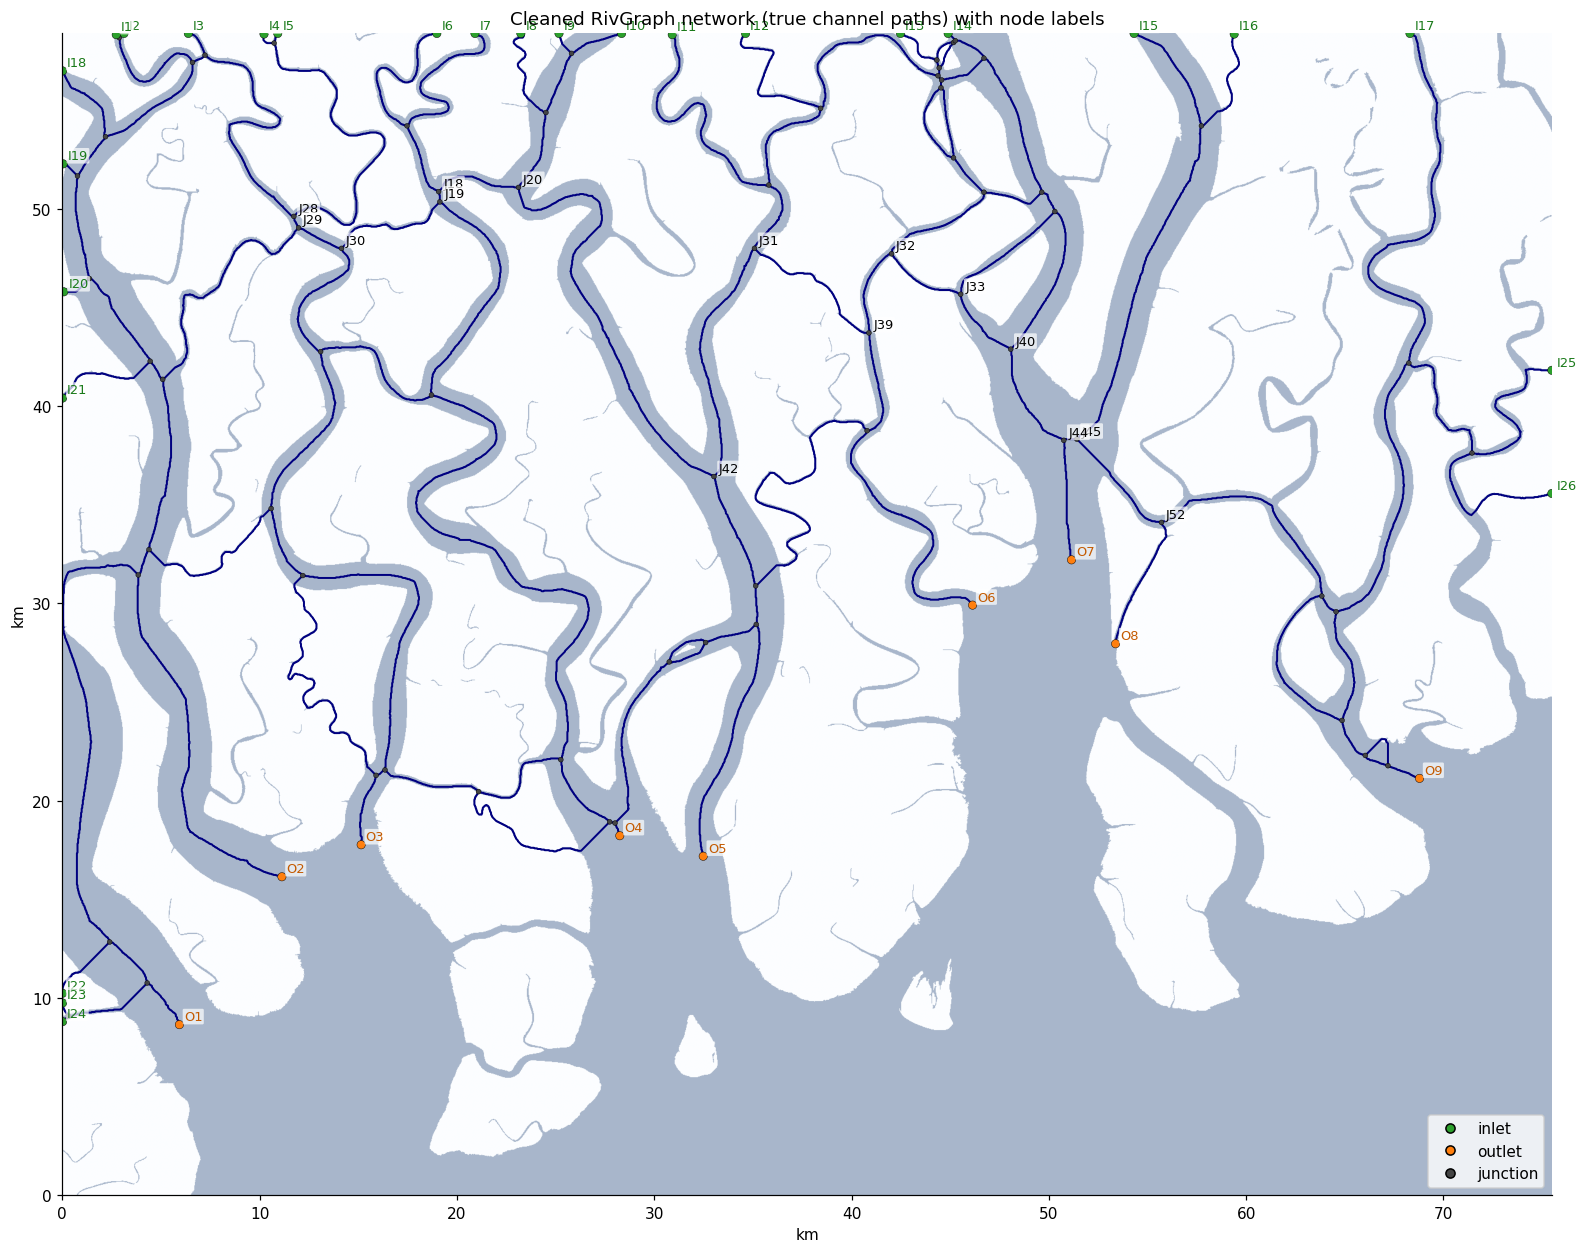

In [2]:
bc = nx.betweenness_centrality(nx.Graph(G))
LAB = {}
for k, n in enumerate(sorted(inlets, key=lambda n: (POS[n][0] if POS[n][1] > EXT_TOP - 1 else 1e3 + (POS[n][0] > 40) * 1e3 - POS[n][1])), 1):
    LAB[n] = f'I{k}'
for k, n in enumerate(sorted(outlets, key=lambda n: POS[n][0]), 1):
    LAB[n] = f'O{k}'
junc = [n for n in G if n not in LAB]
for k, n in enumerate(sorted(junc, key=lambda n: (-(POS[n][1] // 5), POS[n][0])), 1):
    LAB[n] = f'J{k}'
SHOW = set(inlets) | set(outlets) | set(sorted(junc, key=bc.get, reverse=True)[:15])

labels_df = pd.DataFrame([{'label': LAB[n], 'rivgraph_node_id': n, 'kind': G.nodes[n]['kind'], 'degree': G.degree(n),
                           'x_km': round(POS[n][0], 2), 'y_km': round(POS[n][1], 2),
                           'x_utm': round(G.nodes[n]['pos'][0], 1), 'y_utm': round(G.nodes[n]['pos'][1], 1),
                           'betweenness': round(bc[n], 4)} for n in G])
labels_df['order'] = labels_df['label'].str[0].map({'I': 0, 'O': 1, 'J': 2}) * 1000 + labels_df['label'].str[1:].astype(int)
labels_df = labels_df.sort_values('order').drop(columns='order')
labels_df.to_csv('example_2016/node_labels.csv', index=False)

def put_labels(ax, pos, fs=7.5):
    for n in SHOW:
        x, y = pos[n]
        ax.annotate(LAB[n], (x, y), xytext=(3, 3), textcoords='offset points', fontsize=fs,
                    color={'inlet': '#1a7a1a', 'outlet': '#c45a00', 'junction': 'k'}[G.nodes[n]['kind']],
                    bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.7))

def draw_plain(ax, pos):
    # undirected, unweighted; parallel links drawn as two arcs so their loop stays visible
    for (u, v), m in pd.Series([tuple(sorted((u, v), key=str)) for u, v in G.edges()]).value_counts().items():
        (x0, y0), (x1, y1) = pos[u], pos[v]
        for j in range(m):
            off = 0 if m == 1 else (j - (m - 1) / 2) * 0.35
            mx, my = (x0 + x1) / 2 - off * (y1 - y0), (y0 + y1) / 2 + off * (x1 - x0)
            t = np.linspace(0, 1, 20)
            ax.plot((1 - t)**2 * x0 + 2 * (1 - t) * t * mx + t**2 * x1, (1 - t)**2 * y0 + 2 * (1 - t) * t * my + t**2 * y1, color='#555', lw=1)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[30 if G.nodes[n]['kind'] != 'junction' else 12 for n in G],
                           node_color=[KIND_COL[G.nodes[n]['kind']] for n in G], edgecolors='k', linewidths=0.3)
    put_labels(ax, pos)

water = net['water']
fig, ax = plt.subplots(figsize=(15, 11.5))
ax.imshow(water, cmap='Blues', alpha=0.35, extent=EXT)
for *_, d in G.edges(data=True):
    rr, cc = np.unravel_index(d['idx'], rn.imshape)
    ax.plot((cc + 0.5) * T.a / 1e3, EXT[3] - (rr + 0.5) * (-T.e) / 1e3, color='navy', lw=1.3)
nx.draw_networkx_nodes(G, POS, ax=ax, node_size=[30 if G.nodes[n]['kind'] != 'junction' else 10 for n in G],
                       node_color=[KIND_COL[G.nodes[n]['kind']] for n in G], edgecolors='k', linewidths=0.3)
put_labels(ax, POS, 8.5)
ax.set_xlim(EXT[:2]); ax.set_ylim(EXT[2:]); ax.set_xlabel('km'); ax.set_ylabel('km'); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ax.set_title('Cleaned RivGraph network (true channel paths) with node labels')
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=c, mec='k', label=k) for k, c in KIND_COL.items()], loc='lower right')
plt.tight_layout(); plt.savefig('example_2016/cleaned_network_labelled.png', dpi=130); plt.show()

### The same network as a plain node–edge graph (no weights, no direction)

Left: nodes at their map positions, links as straight lines. Right: the same graph in a topological layout (Kamada–Kawai, started from the map positions), which spreads nodes by graph distance and makes the loops easier to see.
Parallel links (two channels between the same pair of nodes) are drawn as two arcs.

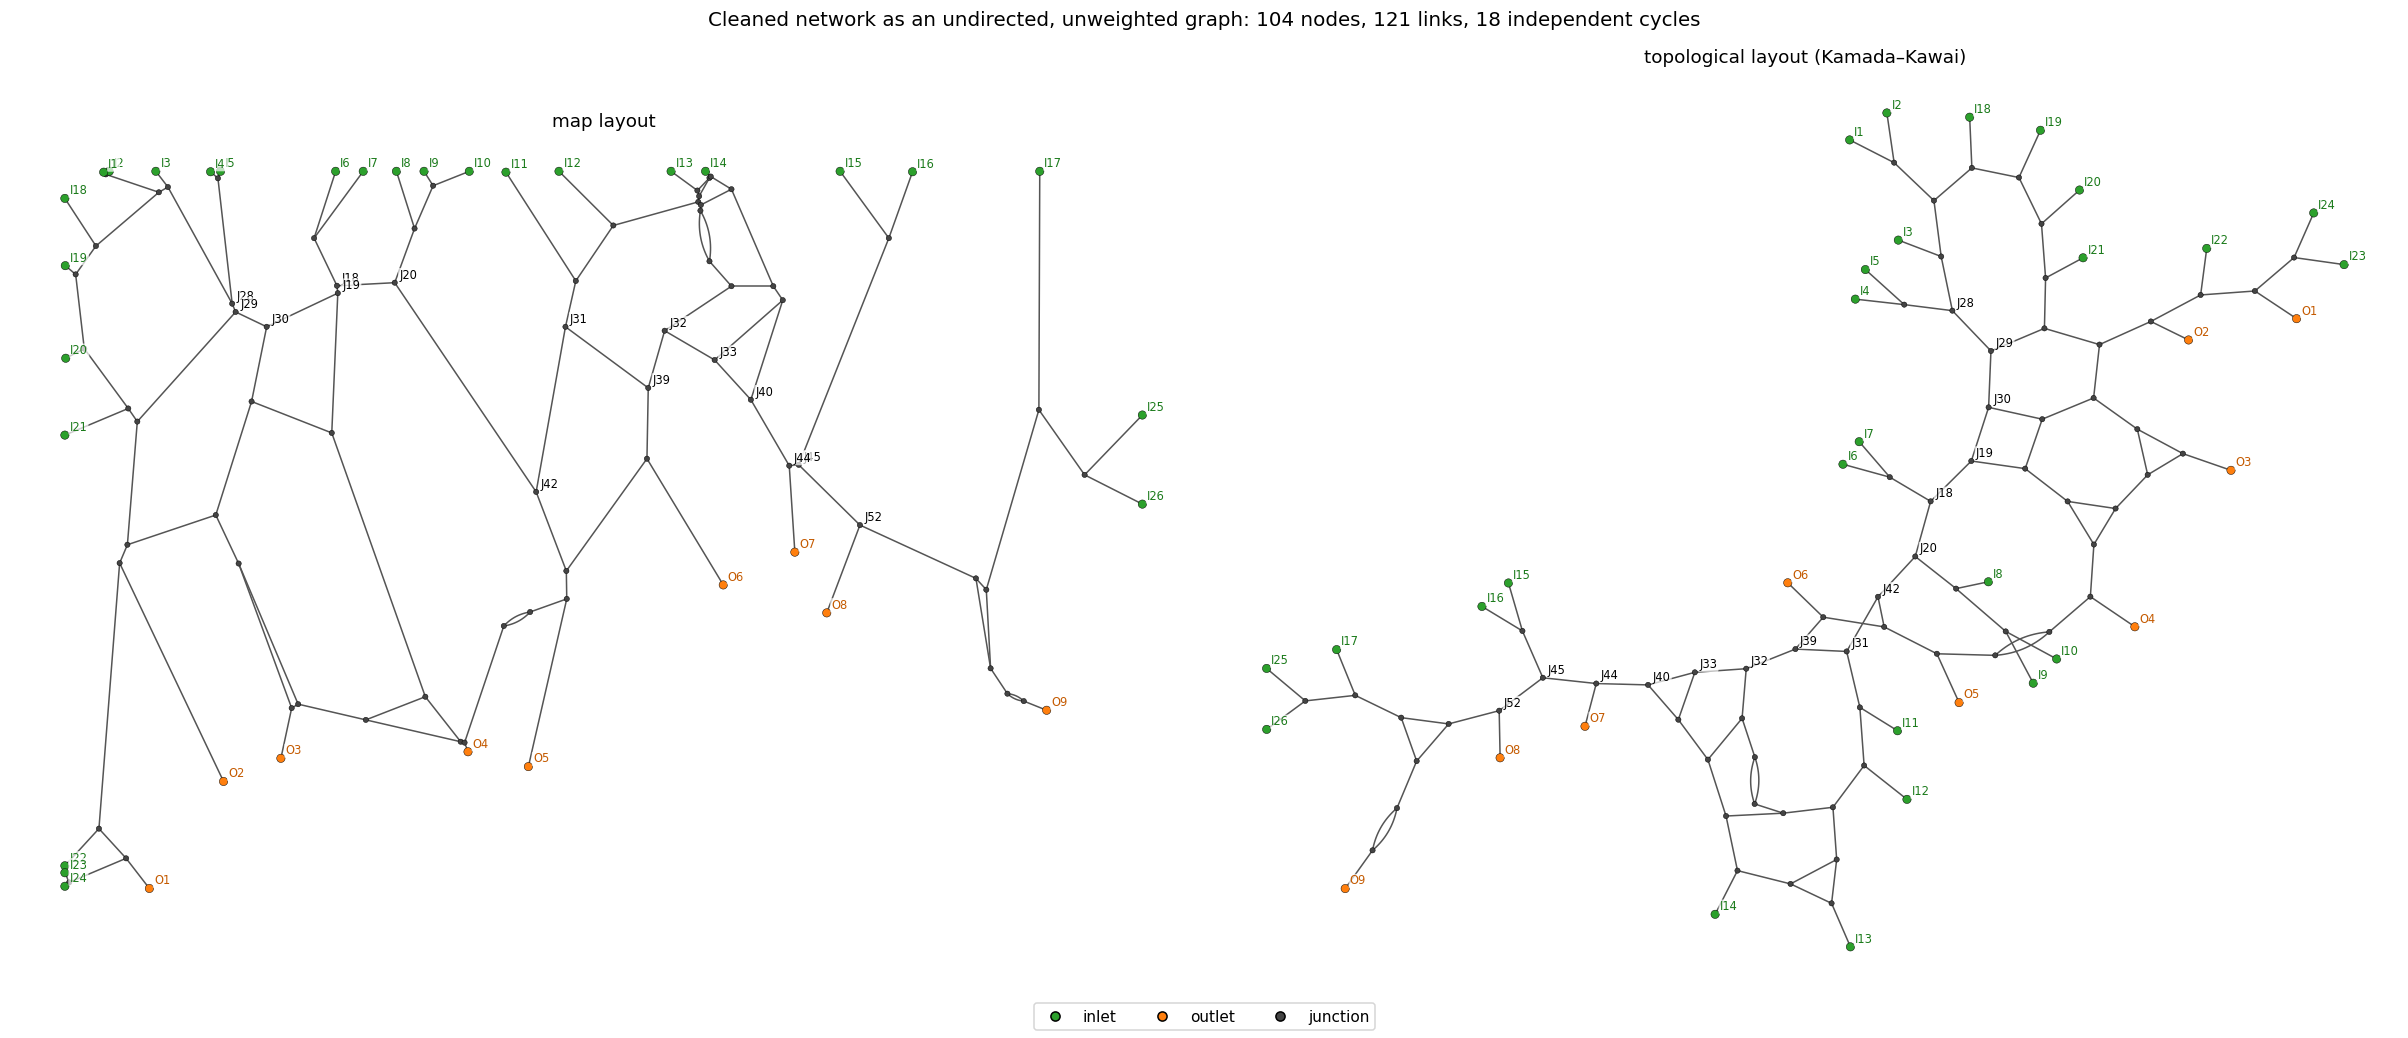

,label,rivgraph_node_id,kind,degree,x_km,y_km,x_utm,y_utm,betweenness
81,I1,15,inlet,1,2.73,58.82,712593.8,2452999.4,0.0000
80,I2,0,inlet,1,3.13,58.88,712986.4,2453060.5,0.0000
55,I3,1,inlet,1,6.39,58.88,716248.4,2453060.5,0.0000
40,I4,13,inlet,1,10.22,58.85,720084.2,2453029.9,0.0000
41,I5,2,inlet,1,10.92,58.88,720778.9,2453060.5,0.0000
27,I6,3,inlet,1,18.98,58.88,728843.2,2453060.5,0.0000
30,I7,4,inlet,1,20.92,58.88,730776.2,2453060.5,0.0000
37,I8,5,inlet,1,23.24,58.88,733101.9,2453060.5,0.0000
39,I9,6,inlet,1,25.17,58.88,735034.9,2453060.5,0.0000
38,I10,7,inlet,1,28.35,58.88,738206.2,2453060.5,0.0000


In [3]:
P = nx.Graph(G)
topo = nx.kamada_kawai_layout(P, pos={n: np.array(POS[n]) for n in P})
topo = {n: (xy[0] * 40, xy[1] * 40) for n, xy in topo.items()}
fig, axs = plt.subplots(1, 2, figsize=(22, 9.5))
draw_plain(axs[0], POS); axs[0].set_aspect('equal'); axs[0].set_title('map layout'); axs[0].axis('off')
draw_plain(axs[1], topo); axs[1].set_aspect('equal'); axs[1].set_title('topological layout (Kamada–Kawai)'); axs[1].axis('off')
fig.suptitle(f'Cleaned network as an undirected, unweighted graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} links, '
             f'{G.number_of_edges() - G.number_of_nodes() + 1} independent cycles', fontsize=13)
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=c, mec='k', label=k) for k, c in KIND_COL.items()], loc='lower center', ncol=3)
plt.tight_layout(); plt.savefig('example_2016/cleaned_network_node_edge.png', dpi=130); plt.show()
labels_df.head(40)

## 1. What the random trees look like

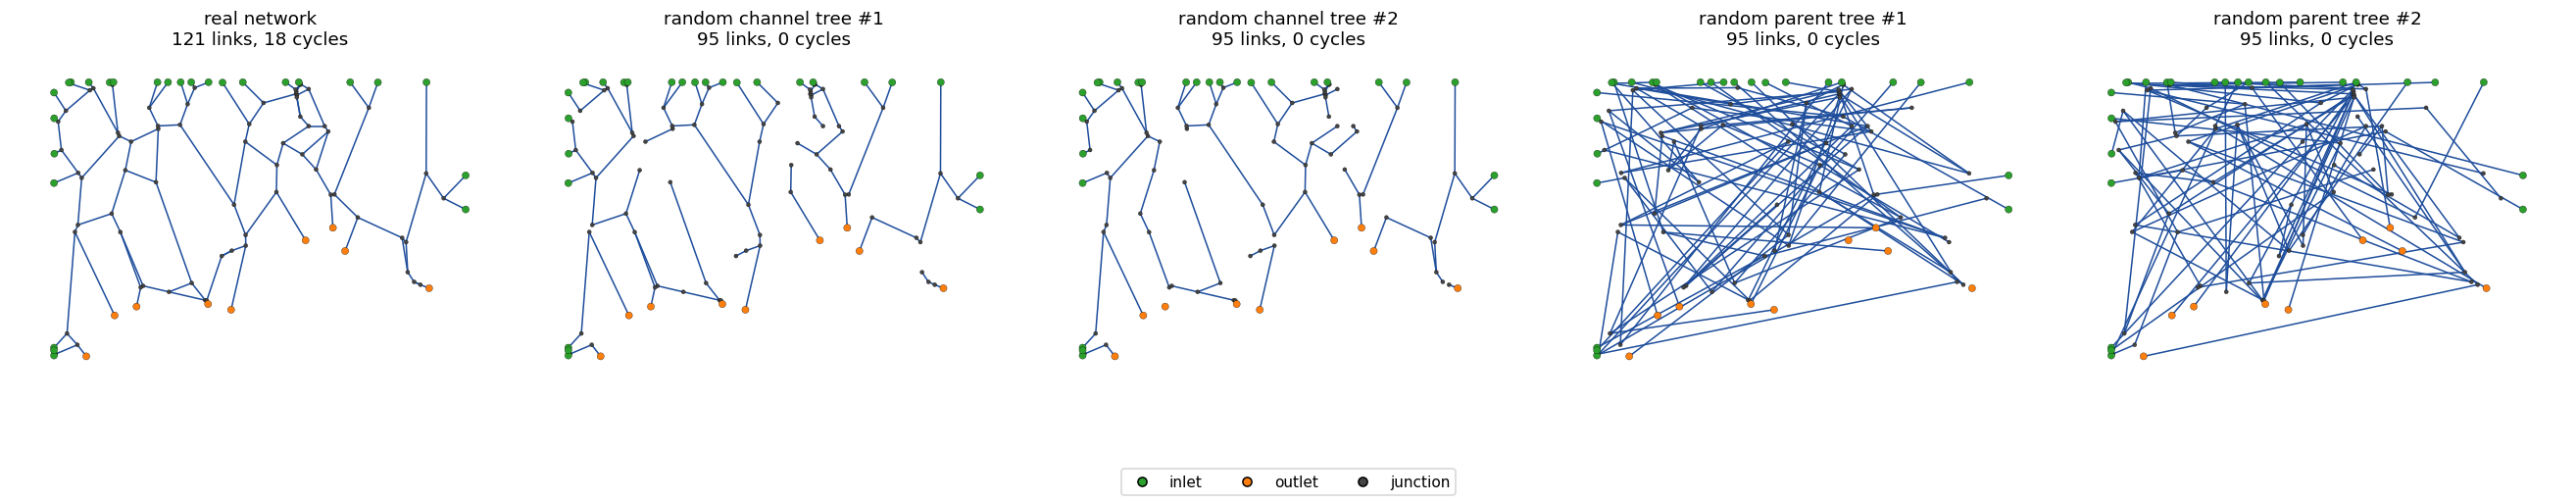

In [4]:
rng = np.random.default_rng(42)
examples = [('real network', G)] + \
           [(f'random channel tree #{i+1}', tn.random_channel_tree(G, outlets, rng)[1]) for i in range(2)] + \
           [(f'random parent tree #{i+1}', tn.random_parent_tree(G, inlets, outlets, rng)[1]) for i in range(2)]

fig, axs = plt.subplots(1, 5, figsize=(24, 5.2))
for ax, (title, g) in zip(axs, examples):
    nx.draw_networkx_edges(g, POS, ax=ax, edge_color='#1f4e9c', width=1)
    nx.draw_networkx_nodes(G, POS, ax=ax, node_size=[22 if G.nodes[n]['kind'] != 'junction' else 7 for n in G],
                           node_color=[KIND_COL[G.nodes[n]['kind']] for n in G], edgecolors='k', linewidths=0.2)
    ax.set_title(f'{title}\n{g.number_of_edges()} links, {g.number_of_edges() - g.number_of_nodes() + nx.number_connected_components(g)} cycles')
    ax.set_aspect('equal'); ax.axis('off')
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=c, mec='k', label=k) for k, c in KIND_COL.items()], loc='lower center', ncol=3)
plt.tight_layout(); plt.savefig('example_2016/null_examples.png', dpi=120); plt.show()

## 2. The parameters, and what each one tells us

Grouped by the question they answer. "**Tree value**" is the value *every* tree has by definition. If it's blank, the value varies from tree to tree.

| Group | Parameter | Definition | Tree value | Why it matters for the Sundarbans |
|---|---|---|---|---|
| **A. Loops / redundancy** | independent cycles | E − V + C | 0 | number of loops, the most direct "distance from a tree" |
| | meshedness | cycles ÷ max possible in a planar graph (2V − 5) | 0 | loopiness independent of size, so it can be compared across dates and resolutions |
| | bridge share | share of links whose loss disconnects the network (`nx.bridges`) | 1 | how fragile the network is to a channel silting up |
| | alternative paths per inlet | distinct downstream routes to the sea (log₁₀) | 0 (=1 path) | Tejedor's *N<sub>ap</sub>*: choice of route |
| | outlets reachable per inlet | | 1 | how widely water (and sediment, salt) from one inlet can spread along the coast |
| | fork share | share of nodes where the flow splits (out-degree ≥ 2) | 0 | distributary character, the opposite of a tributary tree |
| | resistance / path length | effective resistance inlet → sea ÷ links on shortest path | 1 | Tejedor's normalised resistance distance: parallel paths lower it |
| **B. Path structure** | mean & longest inlet → sea path | links on shortest path from inlet to the sea | | how deep the network is |
| | inlet path spread | coefficient of variation of those path lengths | | similar vs very different inlet depths |
| | resistance inlet → sea (Ω) | 1 Ω per link | | how hard it is to push flow through: lower = easier exchange |
| | global efficiency | mean 1/shortest-path over all node pairs | | how easily any point reaches any other |
| **C. Robustness / load** | algebraic connectivity λ₂ | 2nd-smallest Laplacian eigenvalue | | how hard it is to cut the network in two |
| | edge betweenness Gini | inequality of edge betweenness (0 = even, 1 = all on one link) | | do a few trunk channels carry all routes? |
| | robustness curve | share of inlets still reaching the sea vs share of links removed at random | | resilience to channels silting up |
| **D. Shape** | dead-end junctions | junctions with only one link | | a tree with these node counts must leave dead ends |
| | degree-3 share | | | real junctions are all degree 3 |
| | width function | number of nodes at each hop distance from the sea | | Tejedor's delta width function: where the network is wide or narrow |

For **path, resistance, efficiency and λ₂**, the whole sea is one node (`SEA`) joined to every outlet, so every graph is connected and every inlet has a distance to the sea.

## 3. Generate the ensembles and compute every parameter

In [5]:
N = 1000
rng = np.random.default_rng(0)
real = pd.Series(tn.compare_metrics(G, D, inlets, outlets), name='real')
ens = {'channel tree': [], 'parent tree': []}
for _ in range(N):
    TD, TU = tn.random_channel_tree(G, outlets, rng); ens['channel tree'].append(tn.compare_metrics(TU, TD, inlets, outlets))
    TD, TU = tn.random_parent_tree(G, inlets, outlets, rng); ens['parent tree'].append(tn.compare_metrics(TU, TD, inlets, outlets))
ens = {k: pd.DataFrame(v) for k, v in ens.items()}

def pct(x, s):     # percentile of the real value within the null distribution
    return 100 * (np.mean(s < x) + 0.5 * np.mean(s == x))

rows = {}
for p in real.index:
    r = {'real': real[p]}
    for k, df in ens.items():
        s = df[p]
        r[f'{k} mean'] = s.mean(); r[f'{k} sd'] = s.std()
        r[f'{k} z'] = (real[p] - s.mean()) / s.std() if s.std() > 1e-9 else np.nan   # nan = same value in every tree
        r[f'{k} percentile'] = pct(real[p], s)
    rows[p] = r
table = pd.DataFrame(rows).T
table.to_csv('example_2016/real_vs_random_trees_2016-01-18.csv')
table.style.format('{:.3g}', na_rep='fixed').background_gradient(subset=['channel tree z', 'parent tree z'], cmap='RdBu_r', vmin=-10, vmax=10)

,real,channel tree mean,channel tree sd,channel tree z,channel tree percentile,parent tree mean,parent tree sd,parent tree z,parent tree percentile
independent cycles,18,0,0,fixed,100,0,0,fixed,100
meshedness,0.0887,0,0,fixed,100,0,0,fixed,100
bridge share,0.43,1,0,fixed,0,1,0,fixed,0
alt. paths per inlet (log10),2.07,0,0,fixed,100,0,0,fixed,100
outlets reachable per inlet,4.35,1,0,fixed,100,1,0,fixed,100
fork share (water splits),0.25,0,0,fixed,100,0,0,fixed,100
dead-end junctions,0,0.093,0.0181,-5.14,0,0.11,0.0187,-5.87,0
mean inlet→sea path (links),6.15,9.27,1.79,-1.74,0,5.21,0.46,2.05,96.2
longest inlet→sea path (links),9,16.1,3.78,-1.88,0,8.82,1.32,0.133,59.2
inlet path spread (CV),0.28,0.408,0.0718,-1.77,2.2,0.352,0.0592,-1.21,10.7


## 4. Group A: what no tree can have

These parameters have **the same value in every tree**, so the comparison is real vs. one number.
Each bar is shown as a multiple of the tree value, or on its own scale where the tree value is 0.

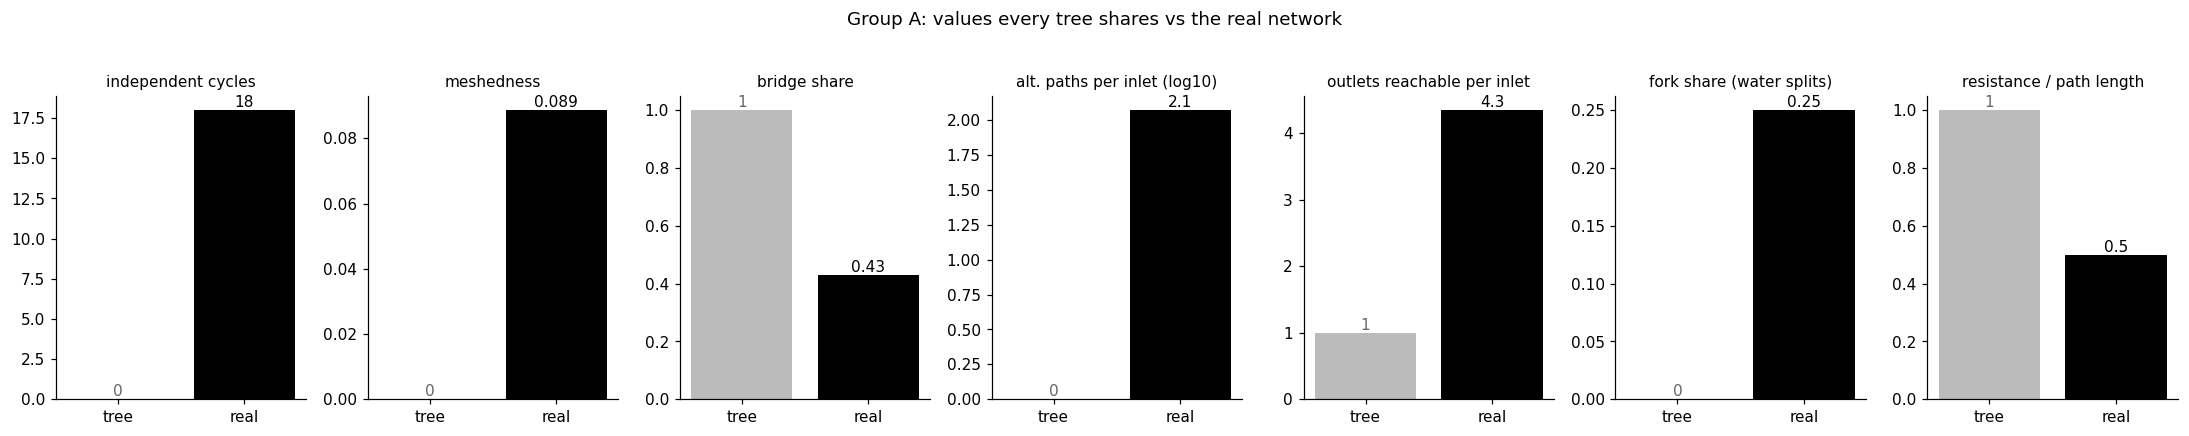

In [6]:
fixedA = ['independent cycles', 'meshedness', 'bridge share', 'alt. paths per inlet (log10)',
          'outlets reachable per inlet', 'fork share (water splits)', 'resistance / path length']
tree_val = ens['channel tree'][fixedA].mean()
fig, axs = plt.subplots(1, len(fixedA), figsize=(20, 3.8))
for ax, p in zip(axs, fixedA):
    ax.bar(['tree', 'real'], [tree_val[p], real[p]], color=['#bbbbbb', 'black'])
    ax.set_title(p, fontsize=10)
    ax.text(1, real[p], f'{real[p]:.2g}', ha='center', va='bottom')
    ax.text(0, tree_val[p], f'{tree_val[p]:.2g}', ha='center', va='bottom', color='0.4')
plt.suptitle('Group A: values every tree shares vs the real network', y=1.03)
plt.tight_layout(); plt.savefig('example_2016/groupA_fixed.png', dpi=120, bbox_inches='tight'); plt.show()

## 5. Groups B–D: where the real network sits among 1,000 random trees

Blue = random channel trees, orange = random parent trees, black line = real network.
The number in each panel is the real network's percentile within each null: below 2.5 or above 97.5 means "outside what random trees produce".

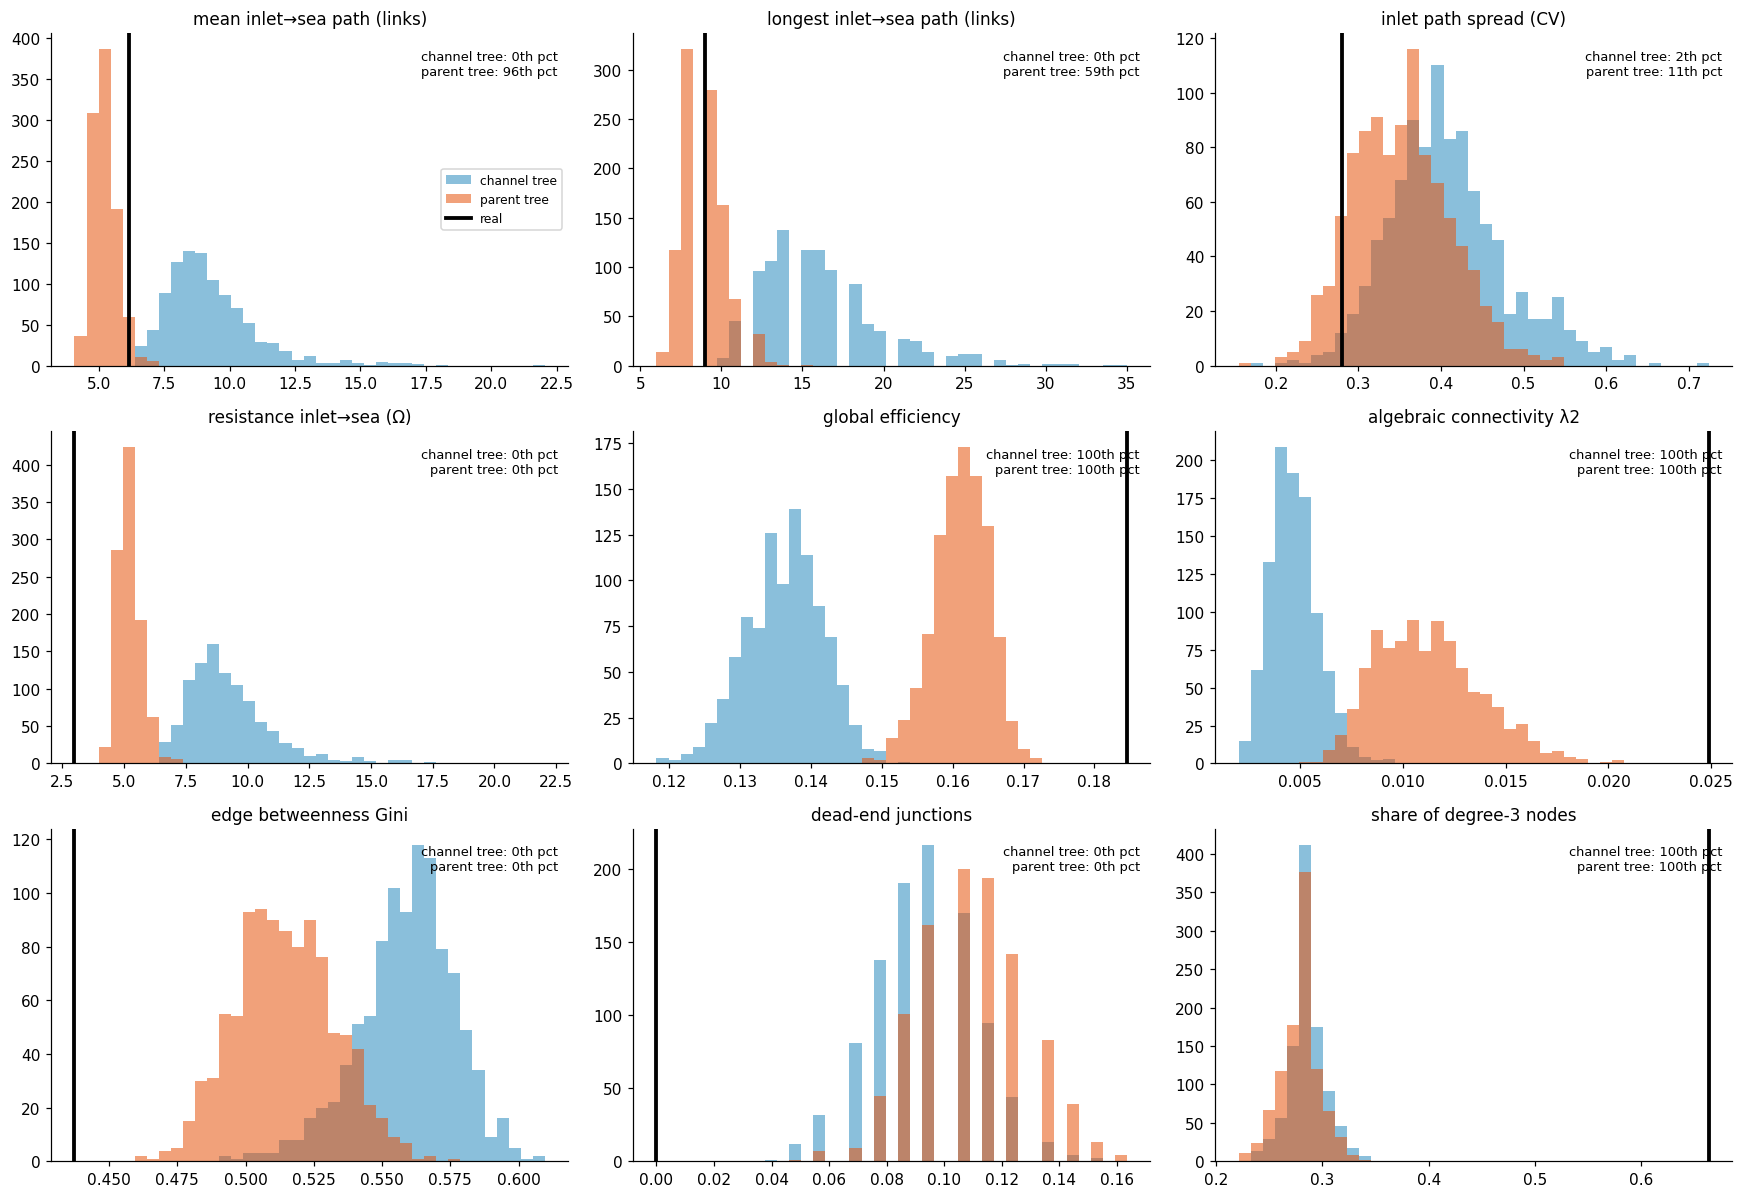

In [7]:
varying = ['mean inlet→sea path (links)', 'longest inlet→sea path (links)', 'inlet path spread (CV)',
           'resistance inlet→sea (Ω)', 'global efficiency', 'algebraic connectivity λ2',
           'edge betweenness Gini', 'dead-end junctions', 'share of degree-3 nodes']
fig, axs = plt.subplots(3, 3, figsize=(16, 11))
for ax, p in zip(axs.ravel(), varying):
    lo = min(ens['channel tree'][p].min(), ens['parent tree'][p].min(), real[p])
    hi = max(ens['channel tree'][p].max(), ens['parent tree'][p].max(), real[p])
    bins = np.linspace(lo, hi, 40) if hi > lo else 10
    for k, df in ens.items():
        ax.hist(df[p], bins=bins, color=COL[k], alpha=0.55, label=k)
    ax.axvline(real[p], color='k', lw=2.5, label='real')
    ax.set_title(p, fontsize=11)
    ax.text(0.98, 0.95, '\n'.join(f'{k}: {table.loc[p, k + " percentile"]:.0f}th pct' for k in ens),
            transform=ax.transAxes, ha='right', va='top', fontsize=8.5)
axs[0, 0].legend(loc='center right', fontsize=8)
plt.tight_layout(); plt.savefig('example_2016/fingerprint_hist.png', dpi=120); plt.show()

### How far from random trees, in standard deviations (z-score)

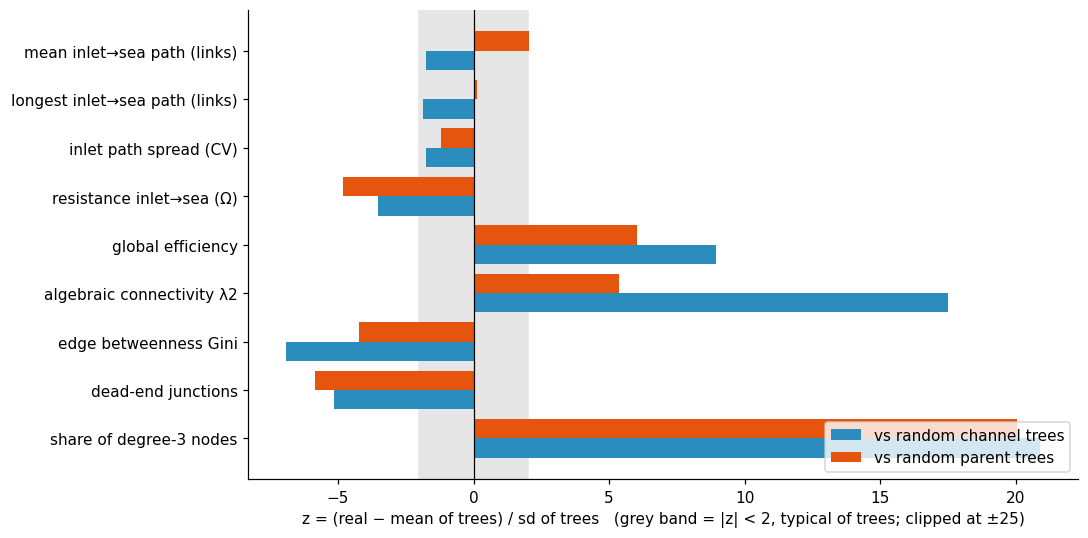

In [8]:
z = table.loc[varying, ['channel tree z', 'parent tree z']]
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(varying))
ax.barh(y + 0.2, z['channel tree z'].clip(-25, 25), 0.4, color=COL['channel tree'], label='vs random channel trees')
ax.barh(y - 0.2, z['parent tree z'].clip(-25, 25), 0.4, color=COL['parent tree'], label='vs random parent trees')
ax.axvspan(-2, 2, color='0.9', zorder=0); ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(y, varying); ax.invert_yaxis(); ax.set_xlabel('z = (real − mean of trees) / sd of trees   (grey band = |z| < 2, typical of trees; clipped at ±25)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.savefig('example_2016/zscores.png', dpi=120); plt.show()

## 6. Robustness: cutting channels at random

Remove a random share of links (as if channels silted up) and record what share of inlets can still reach the sea.
Curves are averages over 10 random removals; bands are the 5–95% range over 300 trees of each kind.

area under curve (1 = never disconnects): {'real': 0.451, 'channel tree': 0.224, 'parent tree': 0.337}


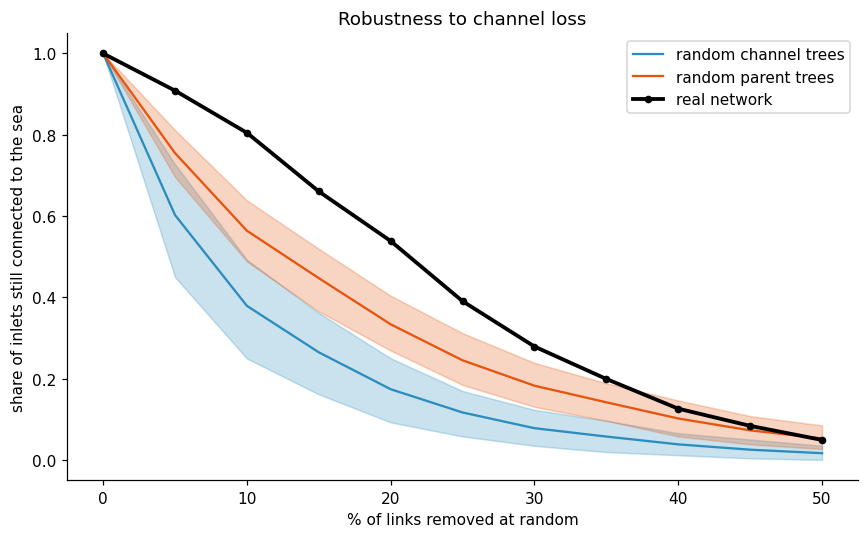

In [9]:
fracs = np.linspace(0, 0.5, 11)
rng = np.random.default_rng(1)
real_curve = tn.robustness_curve(G, inlets, outlets, fracs, 40, rng)
curves = {'channel tree': [], 'parent tree': []}
for _ in range(300):
    curves['channel tree'].append(tn.robustness_curve(tn.random_channel_tree(G, outlets, rng)[1], inlets, outlets, fracs, 10, rng))
    curves['parent tree'].append(tn.robustness_curve(tn.random_parent_tree(G, inlets, outlets, rng)[1], inlets, outlets, fracs, 10, rng))

fig, ax = plt.subplots(figsize=(8, 5))
for k, cs in curves.items():
    cs = np.array(cs)
    ax.fill_between(fracs * 100, *np.percentile(cs, [5, 95], axis=0), color=COL[k], alpha=0.25)
    ax.plot(fracs * 100, cs.mean(0), color=COL[k], label=f'random {k}s')
ax.plot(fracs * 100, real_curve, 'k-o', lw=2.5, ms=4, label='real network')
ax.set_xlabel('% of links removed at random'); ax.set_ylabel('share of inlets still connected to the sea')
ax.legend(); ax.set_title('Robustness to channel loss')
auc = {'real': np.trapz(real_curve, fracs) / fracs[-1]} | {k: np.trapz(np.mean(c, 0), fracs) / fracs[-1] for k, c in curves.items()}
print('area under curve (1 = never disconnects):', {k: round(v, 3) for k, v in auc.items()})
plt.tight_layout(); plt.savefig('example_2016/robustness.png', dpi=120); plt.show()

## 7. Width function: how many nodes at each distance from the sea

Tejedor et al. (2015, §8) use this to tell *divergent*, *convergent* and *confined* deltas apart.

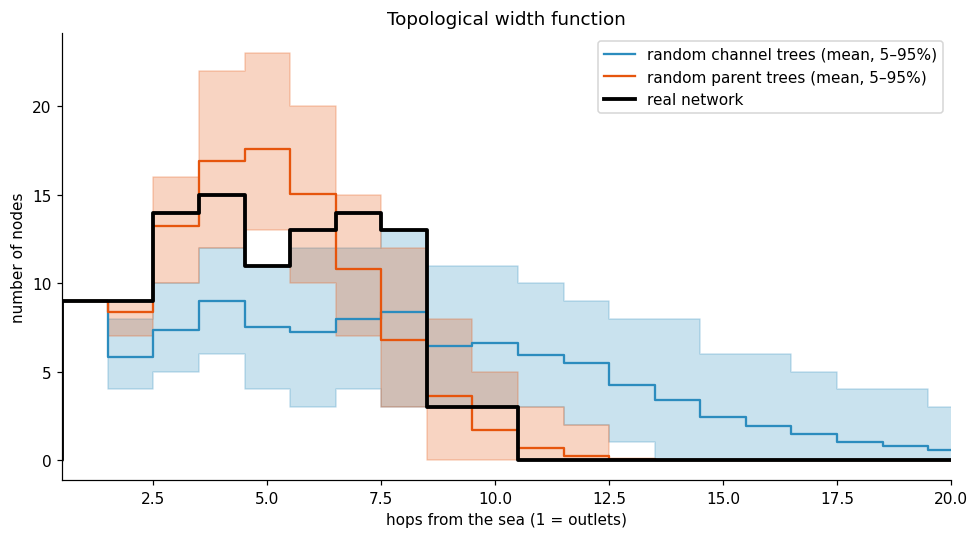

In [10]:
rng = np.random.default_rng(2)
maxhop = 25
wf = {'channel tree': [], 'parent tree': []}
for _ in range(N):
    wf['channel tree'].append(tn.width_function(tn._with_sea(tn.random_channel_tree(G, outlets, rng)[1], outlets), maxhop))
    wf['parent tree'].append(tn.width_function(tn._with_sea(tn.random_parent_tree(G, inlets, outlets, rng)[1], outlets), maxhop))
wf_real = tn.width_function(tn._with_sea(G, outlets), maxhop)
x = np.arange(maxhop + 1)
fig, ax = plt.subplots(figsize=(9, 5))
for k, w in wf.items():
    w = np.array(w)
    ax.fill_between(x, *np.percentile(w, [5, 95], axis=0), color=COL[k], alpha=0.25, step='mid')
    ax.step(x, w.mean(0), where='mid', color=COL[k], label=f'random {k}s (mean, 5–95%)')
ax.step(x, wf_real, where='mid', color='k', lw=2.5, label='real network')
ax.set_xlim(0.5, 20); ax.set_xlabel('hops from the sea (1 = outlets)'); ax.set_ylabel('number of nodes')
ax.legend(); ax.set_title('Topological width function'); plt.tight_layout(); plt.savefig('example_2016/width_function.png', dpi=120); plt.show()

## 8. Degree composition

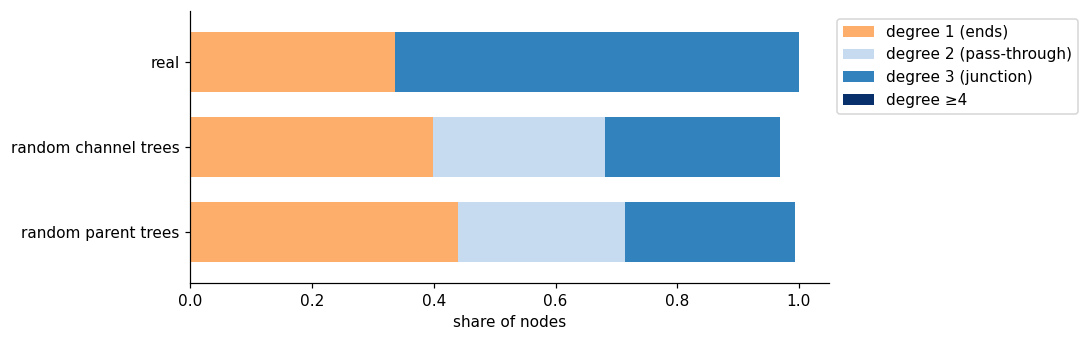

,degree 1 (ends),degree 2 (pass-through),degree 3 (junction),degree ≥4
real,0.337,0.000,0.663,0.0
random channel trees,0.399,0.283,0.287,0.0
random parent trees,0.440,0.275,0.279,0.0


In [11]:
def deg_mix(g):
    d = np.array([v for _, v in g.degree()])
    return pd.Series({'degree 1 (ends)': np.mean(d == 1), 'degree 2 (pass-through)': np.mean(d == 2), 'degree 3 (junction)': np.mean(d == 3), 'degree ≥4': np.mean(d >= 4)})
rng = np.random.default_rng(3)
mix = pd.DataFrame({'real': deg_mix(G),
                    'random channel trees': pd.concat([deg_mix(tn.random_channel_tree(G, outlets, rng)[1]) for _ in range(200)], axis=1).mean(1),
                    'random parent trees': pd.concat([deg_mix(tn.random_parent_tree(G, inlets, outlets, rng)[1]) for _ in range(200)], axis=1).mean(1)}).T
ax = mix.plot.barh(stacked=True, figsize=(10, 3.2), color=['#fdae6b', '#c6dbef', '#3182bd', '#08306b'], width=0.7)
ax.set_xlabel('share of nodes'); ax.legend(bbox_to_anchor=(1, 1)); ax.invert_yaxis()
plt.tight_layout(); plt.savefig('example_2016/degree_mix.png', dpi=120); plt.show()
mix.round(3)

## 9. What the comparison shows (filled in from this run)


All numbers are from this run. Null means are over 1,000 trees; "pct" is the real value's percentile within that null.

**A. What no tree can have** (every tree has the same value)

| parameter | real | every tree |
|---|---|---|
| independent cycles / meshedness | 18 / 0.089 | 0 / 0 |
| bridge share | 0.43 | 1 |
| alternative paths per inlet | ~118 (10^2.07) | 1 |
| outlets reachable per inlet | 4.3 of 9 | 1 |
| fork share (nodes where flow splits) | 25% | 0% |
| resistance ÷ path length | 0.50 | 1 |

On average, parallel routes halve the effective resistance from an inlet to the sea, and water from one inlet can reach about 4 outlets instead of 1.

**B. Path structure: the real network sits *between* the two nulls**

* Mean inlet → sea path: real **6.2 links**. That is shorter than every random channel tree (mean 9.3, longest 16 vs 9), so the loops act as **shortcuts**.
  It is longer than random parent trees (5.2, 96th pct), because those join nodes regardless of distance. Geography makes real paths longer than random wiring would.
* Resistance inlet → sea is 3.0 Ω, versus 9.3 and 5.2 Ω: **below every tree of both kinds**. This is the clearest single effect of the loops.
* Global efficiency (0.185) is above every tree.

**C. Robustness and load**

* λ₂ = 0.025: about 5× random channel trees and 2× random parent trees. The real network is much harder to cut in two.
* Edge betweenness Gini 0.44 vs 0.56 / 0.51: routes are spread more evenly. In a tree, a few trunk links carry everything.
* Robustness (area under the curve): real **0.45**, channel trees 0.22, parent trees 0.34. With 10% of links removed at random, the real network keeps ~80% of inlets connected to the sea, against ~38% (channel trees) and ~56% (parent trees).

**D. Shape**

* Width function: the real network is compact, with all nodes within 10 hops of the sea and the bulk at 3–8 hops. Random channel trees stretch out to ~20 hops because cutting loops forces long detours.
  The real network is *wider* than channel trees at 3–8 hops, where its belt of loops sits.
* Dead-end junctions (0 vs ~10%) and degree-3 share (66% vs ~28%) are partly built in. RivGraph's cleaned network has no degree-2 nodes, while a tree on the same nodes can't avoid dead ends and pass-through nodes.
  Treat these as consequences of the loops, not separate findings.

**Which parameters to carry into the 2016–2026 series:** meshedness, bridge share, alternative paths per inlet, resistance ÷ path length, λ₂, edge betweenness Gini and robustness AUC.
Also record each one's **z-score against random channel trees built for the same date**. That null has the same nodes and channels as that date's image, so the z-score corrects for changes in node count, crop or detection between dates. A shift in the z-score is a change in structure, not in size.